# Unsupervised Domain Adaptation: GPL, ICT, TSDAE Comparison
## ITSM Nexus â€” Unsupervised Fine-Tuning Pipeline

This notebook implements and compares three unsupervised domain adaptation methods for semantic search on ServiceNow incident data:

| Method | Type | Key Idea |
|--------|------|----------|
| **ICT** | Self-supervised | Sentence as pseudo-query, passage as document |
| **TSDAE** | Denoising AE | Reconstruct corrupted sentences via encoder-decoder |
| **GPL** | Generative PL | T5-generated queries + cross-encoder scoring + MarginMSE |

**Baseline**: V4 Cosine (MPNet + LoRA, Spearman 0.4949, ROC-AUC 0.7857)

> âš ï¸ Use `data_new/curriculum_training_pairs_*.json` for any supervised comparisons â€” never raw `data/` pairs.

## 1. Import Required Libraries

In [1]:
import sys
import os

# Add conda env DLL paths so numpy/pandas native extensions can find their DLLs
_conda_env = r"c:\Users\donov\miniconda3\envs\itsm"
_dll_paths = [
    _conda_env,
    os.path.join(_conda_env, "Library", "mingw-w64", "bin"),
    os.path.join(_conda_env, "Library", "usr", "bin"),
    os.path.join(_conda_env, "Library", "bin"),
    os.path.join(_conda_env, "Scripts"),
]
for p in _dll_paths:
    if os.path.isdir(p) and p not in os.environ.get("PATH", ""):
        os.add_dll_directory(p)

print(sys.version)
print(sys.executable)
print("DLL paths registered âœ…")


3.11.14 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 18:30:03) [MSC v.1929 64 bit (AMD64)]
c:\Users\donov\miniconda3\envs\itsm\python.exe
DLL paths registered âœ…


In [2]:
# -- Fix 4: ensure sentencepiece is available for T5Tokenizer ------------------
# T5Tokenizer requires sentencepiece at tokenizer-load time.
# Install it, then invalidate Python's import caches so it's visible
# to HuggingFace's internal SentencePieceExtractor in this same kernel session.
import subprocess, sys, importlib

def _ensure_sentencepiece():
    try:
        import sentencepiece as spm
        print(f"✅ sentencepiece already available: {spm.__version__}")
        return True
    except ImportError:
        pass
    print("⏳ Installing sentencepiece …")
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "sentencepiece", "-q"],
        capture_output=True, text=True
    )
    if result.returncode != 0:
        print(f"❌ Install failed:\n{result.stderr}")
        return False
    # Invalidate import caches so newly installed package is discoverable
    importlib.invalidate_caches()
    try:
        import sentencepiece as spm
        print(f"✅ sentencepiece installed: {spm.__version__}")
        # Also force HuggingFace tokenizers to re-check for sentencepiece
        try:
            import tokenizers
            importlib.reload(tokenizers)
        except Exception:
            pass
        return True
    except ImportError:
        print("⚠️  sentencepiece installed but still not importable.")
        print("   ➡️  RESTART the kernel (Kernel → Restart) and re-run all cells.")
        print("      T5 query generation will use ICT-style fallback this run, which is OK.")
        return False

_SP_AVAILABLE = _ensure_sentencepiece()


✅ sentencepiece already available: 0.2.1


In [3]:
# -- External: core ML & data --------------------------------------------------
import os
import json
import random
import logging
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# -- Sentence Transformers ------------------------------------------------------
from sentence_transformers import (
    SentenceTransformer,
    InputExample,
    losses,
    evaluation,
    models,
)
from sentence_transformers.datasets import DenoisingAutoEncoderDataset
from torch.utils.data import DataLoader

# -- Transformers / HF ----------------------------------------------------------
from transformers import T5ForConditionalGeneration, T5Tokenizer, AutoTokenizer
import faiss

# -- BEIR evaluation ------------------------------------------------------------
try:
    from beir import util as beir_util
    from beir.retrieval.evaluation import EvaluateRetrieval
    from beir.retrieval import models as beir_models
    BEIR_AVAILABLE = True
    print("✅ BEIR library found -- will use full BEIR evaluator")
except ImportError:
    BEIR_AVAILABLE = False
    print("⚠️  BEIR not installed -- using custom retrieval evaluator (functionally equivalent)")
    print("   Install with: pip install beir")

# -- UMAP / t-SNE ---------------------------------------------------------------
try:
    import umap
    UMAP_AVAILABLE = True
    print("✅ UMAP found")
except ImportError:
    UMAP_AVAILABLE = False
    print("⚠️  UMAP not found -- t-SNE fallback active. Install: pip install umap-learn")

from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import LabelEncoder

# -- Misc -----------------------------------------------------------------------
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.WARNING)

# -- Reproducibility ------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"\n🖥️  Device: {DEVICE}")
print(f"🔥 PyTorch: {torch.__version__}")
print(f"📅 Run timestamp: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")


✅ BEIR library found -- will use full BEIR evaluator
✅ UMAP found

🖥️  Device: cuda
🔥 PyTorch: 2.9.1+cu130
📅 Run timestamp: 2026-02-25 11:15:26


In [4]:
# -- Project paths (matches ITSM Nexus folder conventions) ---------------------
PROJECT_ROOT = Path(r"c:\Users\donov\Documents\itsm project\Final_nexustism")
NEXUSTISM    = PROJECT_ROOT / "nexustism"
DATA_DIR     = NEXUSTISM / "data"
DATA_NEW_DIR = NEXUSTISM / "data_new"
MODELS_DIR   = NEXUSTISM / "models"
OUTPUT_DIR   = NEXUSTISM / "models" / "unsupervised_runs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Production model (V4 Cosine)
V4_MODEL_PATH = (
    MODELS_DIR
    / "real_servicenow_finetuned_mpnet_lora"
    / "real_servicenow_v2_20260104_2321"
)

# -- Fix 1: Real ServiceNow CSV corpus (was pointing at missing JSON) -----------
INCIDENTS_PATH = DATA_NEW_DIR / "SNow_incident_ticket_data.csv"

print("📁 Project layout:")
for label, p in [
    ("Root",       PROJECT_ROOT),
    ("Data",       DATA_DIR),
    ("Data (new)", DATA_NEW_DIR),
    ("Models",     MODELS_DIR),
    ("Output",     OUTPUT_DIR),
    ("V4 model",   V4_MODEL_PATH),
    ("Corpus",     INCIDENTS_PATH),
]:
    status = "✅" if p.exists() else "❌ (not found)"
    print(f"  {status}  {label:12s}: {p}")

# -- Training hyper-parameters (tune per method below) -------------------------
CONFIG = {
    "base_model":         "sentence-transformers/all-mpnet-base-v2",
    "t5_model":           "BeIR/query-gen-msmarco-t5-base-v1",
    "cross_encoder_model":"cross-encoder/ms-marco-MiniLM-L-6-v2",
    "max_corpus_size":    5_000,          # cap for fast iteration; remove for full run
    "ict_epochs":         6,
    "tsdae_epochs":       1,              # 1 epoch avoids collapse on homogeneous 5K ITSM corpus (was 6)
    "gpl_steps":          5_000,          # Fix 3: was 2K; more steps for MarginMSE convergence
    "batch_size":         16,
    "eval_top_k":         [1, 5, 10],
    "neg_per_query":      5,              # GPL negatives per query
    "queries_per_doc":    3,              # GPL generated queries per document
    "deletion_ratio":     0.3,            # Fix 3: was 0.6; IT tickets are short
}
print("\n⚙️  CONFIG loaded:", json.dumps(CONFIG, indent=2, default=str))


📁 Project layout:
  ✅  Root        : c:\Users\donov\Documents\itsm project\Final_nexustism
  ✅  Data        : c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\data
  ✅  Data (new)  : c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\data_new
  ✅  Models      : c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models
  ✅  Output      : c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\unsupervised_runs
  ✅  V4 model    : c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\real_servicenow_finetuned_mpnet_lora\real_servicenow_v2_20260104_2321
  ✅  Corpus      : c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\data_new\SNow_incident_ticket_data.csv

⚙️  CONFIG loaded: {
  "base_model": "sentence-transformers/all-mpnet-base-v2",
  "t5_model": "BeIR/query-gen-msmarco-t5-base-v1",
  "cross_encoder_model": "cross-encoder/ms-marco-MiniLM-L-6-v2",
  "max_corpus_size": 5000,
  "ict_epochs": 6,
  "tsd

## 2. Load and Preprocess Data

In [5]:
# -- Fix 1: CSV-aware corpus loader ---------------------------------------------

def load_incidents_csv(path: Path, max_docs: int | None = None) -> pd.DataFrame:
    """
    Load ServiceNow incidents from SNow_incident_ticket_data.csv.
    Column mapping:
        Number      -> id
        Description -> text  (only text field in this CSV; no short_description)
        Category    -> category
        Priority    -> priority
        Service     -> service   (SAP / Mulesoft / eWorkplace etc.)
    """
    df = pd.read_csv(path, usecols=["Number", "Description", "Category",
                                     "Priority", "Service"],
                     dtype=str, low_memory=False)
    df = df.rename(columns={
        "Number":      "id",
        "Description": "text",
        "Category":    "category",
        "Priority":    "priority",
        "Service":     "service",
    })
    df = df.dropna(subset=["text"])
    df = df[df["text"].str.strip().str.len() >= 20]
    df = df.fillna("unknown")
    df = df.drop_duplicates("id").reset_index(drop=True)
    if max_docs:
        df = df.head(max_docs)
    return df


def load_incidents_json(path: Path, max_docs: int | None = None) -> pd.DataFrame:
    """Fallback JSON loader for the old servicenow_incidents_full.json format."""
    with open(path, "r", encoding="utf-8") as f:
        raw = json.load(f)
    records = raw if isinstance(raw, list) else list(raw.values())
    if max_docs:
        records = records[:max_docs]
    rows = []
    for rec in records:
        parts = [
            str(rec.get("short_description", "") or ""),
            str(rec.get("description", "")        or ""),
        ]
        text = " ".join(p.strip() for p in parts if p.strip())
        if len(text) < 20:
            continue
        rows.append({
            "id":       str(rec.get("sys_id", rec.get("number", len(rows)))),
            "text":     text,
            "category": str(rec.get("category",       "unknown")),
            "priority": str(rec.get("priority",       "unknown")),
            "service":  str(rec.get("service",        "unknown")),
        })
    return pd.DataFrame(rows).drop_duplicates("id").reset_index(drop=True)


# -- Load corpus ----------------------------------------------------------------
if INCIDENTS_PATH.exists():
    if INCIDENTS_PATH.suffix.lower() == ".csv":
        corpus_df = load_incidents_csv(INCIDENTS_PATH, max_docs=CONFIG["max_corpus_size"])
        print(f"✅ Loaded {len(corpus_df):,} incidents from CSV: {INCIDENTS_PATH.name}")
    else:
        corpus_df = load_incidents_json(INCIDENTS_PATH, max_docs=CONFIG["max_corpus_size"])
        print(f"✅ Loaded {len(corpus_df):,} incidents from JSON: {INCIDENTS_PATH.name}")
else:
    # Synthetic fallback if neither file is present
    print("⚠️  Corpus file not found -- generating synthetic ServiceNow-style data")
    TEMPLATE_TEXTS = [
        "VPN connection dropping every 30 minutes affecting remote workers",
        "Email not syncing on Outlook after Windows update",
        "Password reset required after multiple failed login attempts",
        "Database server unresponsive causing ERP system outage",
        "Printer offline on floor 3, queue jobs stuck",
        "SAP transaction SE16 throwing ABAP dump in production",
        "Network latency spike between data-center and branch office",
        "User cannot log into ServiceNow after MFA enrollment",
        "CPU utilization at 100% on web-app01 server since 08:00",
        "SSL certificate expired on customer-facing portal",
    ]
    CATEGORIES = ["network", "hardware", "software", "database", "security"]
    PRIORITIES = ["1-Critical", "2-High", "3-Moderate", "4-Low"]
    SERVICES   = ["SAP", "Mulesoft/EAI", "eWorkplace", "Network", "Infrastructure"]
    rng = np.random.default_rng(SEED)
    corpus_df = pd.DataFrame({
        "id":       [f"INC{i:05d}" for i in range(CONFIG["max_corpus_size"])],
        "text":     [TEMPLATE_TEXTS[i % len(TEMPLATE_TEXTS)] +
                     f" (ticket #{i}, variant {i // len(TEMPLATE_TEXTS)})"
                     for i in range(CONFIG["max_corpus_size"])],
        "category": rng.choice(CATEGORIES, CONFIG["max_corpus_size"]),
        "priority": rng.choice(PRIORITIES,  CONFIG["max_corpus_size"]),
        "service":  rng.choice(SERVICES,    CONFIG["max_corpus_size"]),
    })
    print(f"✅ Generated {len(corpus_df):,} synthetic incidents")

print(f"\n📊 Corpus shape: {corpus_df.shape}")
print(corpus_df[["category", "priority"]].value_counts().head(12).to_string())
corpus_df.head(3)


✅ Loaded 5,000 incidents from CSV: SNow_incident_ticket_data.csv

📊 Corpus shape: (5000, 5)
category              priority    
Application/Software  3 - Moderate    2470
                      4 - Low         2119
unknown               3 - Moderate     182
                      4 - Low           89
Server                3 - Moderate      37
                      4 - Low           35
Network               4 - Low           34
                      3 - Moderate      20
Application/Software  2 - High           7
                      1 - Critical       3
Hardware              4 - Low            2
                      3 - Moderate       1


,id,text,priority,service,category
0,INC0010171,GRPT not working as expected. ZMMM_PO_REV is n...,4 - Low,SAP,Application/Software
1,INC0010181,eTR-S1-24000073\r\nExchange Rate did not auto ...,4 - Low,eWorkplace (eWorkplace SharePoint & eWorkplace...,Application/Software
2,INC0010188,There is no GRPT maintenance for Sold-To: 3901...,4 - Low,SAP,Application/Software


In [6]:
# -- Text cleaning --------------------------------------------------------------
import re

def clean_text(text: str) -> str:
    text = re.sub(r"https?://\S+", " ", text)           # strip URLs
    text = re.sub(r"[^\x00-\x7F]+", " ", text)          # strip non-ASCII
    text = re.sub(r"\s+", " ", text).strip()             # normalise whitespace
    return text[:512]                                    # cap at 512 chars

corpus_df["text_clean"] = corpus_df["text"].apply(clean_text)

# Ensure service column exists (may not be present in synthetic fallback older runs)
if "service" not in corpus_df.columns:
    corpus_df["service"] = "unknown"

# -- Train / eval split (80 / 20) -----------------------------------------------
from sklearn.model_selection import train_test_split

train_df, eval_df = train_test_split(
    corpus_df, test_size=0.2, random_state=SEED, shuffle=True
)
train_df = train_df.reset_index(drop=True)
eval_df  = eval_df.reset_index(drop=True)

print(f"📚 Train docs : {len(train_df):,}")
print(f"🔍 Eval  docs : {len(eval_df):,}")
print("\n📝 Sample texts:")
for t in train_df["text_clean"].head(3):
    print(f"  • {t[:120]}…")


📚 Train docs : 4,000
🔍 Eval  docs : 1,000

📝 Sample texts:
  • For Consignment Pick-up(Order Type : KA) Return, can not GI because it is disabled. and It is not set up eDO, the output…
  • "Customer duplicate account: - 84981774896 - 84868963694 Pls merge into 1 account only"…
  • """Work Order With WOLI and SOLI"" Report type was a custom report made for PSV. Thus, please limit the user only for PS…


In [7]:
# -- Build a lightweight retrieval evaluator (BEIR-compatible interface) --------

def build_beir_corpus(df: pd.DataFrame) -> dict:
    """Return BEIR-style corpus: {doc_id: {'title': '', 'text': ...}}"""
    return {row.id: {"title": "", "text": row.text_clean}
            for row in df.itertuples()}

def make_pseudo_qrels(eval_df: pd.DataFrame, n_queries: int = 400) -> tuple:
    """
    Create pseudo-QRELs using the FIRST SENTENCE of each incident as the query
    and the full text as the retrieval target.

    Fix 2: Real ServiceNow tickets have a structured description. The first
    sentence (before the first period/newline) captures the problem statement --
    exactly what a user would type as a search query. This is far more realistic
    than a 10-word prefix, which on real IT tickets often captures system headers
    or ticket metadata rather than the meaningful problem description.

    Query selection rules:
      - First sentence split on [.!?\\n] (whichever comes first)
      - Query must be >= 8 words and >= 20 chars (screens out header-only tickets)
      - Document must have content beyond the query (>= 2 sentences or >= 50 chars remain)
    """
    sample  = eval_df.sample(min(n_queries * 2, len(eval_df)), random_state=SEED)
    queries = {}
    qrels   = {}

    for row in sample.itertuples():
        if len(queries) >= n_queries:
            break
        text    = row.text_clean
        # Split on first sentence-ending punctuation or newline
        parts   = re.split(r"(?<=[.!?\n])\s+", text, maxsplit=1)
        q_text  = parts[0].strip()
        remainder = parts[1].strip() if len(parts) > 1 else ""

        q_words = q_text.split()
        # Quality gates: meaningful first sentence + document has more content
        if len(q_words) < 8 or len(q_text) < 20:
            continue
        if len(remainder) < 20:   # doc body too short after the query sentence
            continue

        qid          = f"q_{row.id}"
        queries[qid] = q_text
        qrels[qid]   = {row.id: 1}

    # Fallback if not enough first-sentence pairs: use first 10 words
    if len(queries) < 50:
        print("⚠️  First-sentence split yielded too few pairs -- falling back to 10-word prefix")
        for row in eval_df.itertuples():
            if len(queries) >= n_queries:
                break
            words  = row.text_clean.split()
            q_text = " ".join(words[:10])
            if len(words) < 12:
                continue
            qid          = f"q_{row.id}"
            if qid in queries:
                continue
            queries[qid] = q_text
            qrels[qid]   = {row.id: 1}

    return queries, qrels

eval_corpus  = build_beir_corpus(eval_df)
eval_queries, eval_qrels = make_pseudo_qrels(eval_df)

print(f"📒 Eval corpus  : {len(eval_corpus):,} docs")
print(f"❓ Eval queries : {len(eval_queries):,}")
print(f"\n📝 Query vs document example (should be different):")
sample_qid = next(iter(eval_queries))
sample_did = next(iter(eval_qrels[sample_qid]))
print(f"  Query : '{eval_queries[sample_qid]}'")
print(f"  Target: '{eval_corpus[sample_did]['text'][:160]}…'")


📒 Eval corpus  : 1,000 docs
❓ Eval queries : 386

📝 Query vs document example (should be different):
  Query : 'There is an extra character '8' in Ref Key 1 for invoice no.'
  Target: 'There is an extra character '8' in Ref Key 1 for invoice no. 300186587. Glovia does not have this character but it is found in API, Miro and FI invoice.…'


In [8]:
# -- Custom retrieval evaluator (used when BEIR is unavailable) -----------------

def retrieval_evaluate(
    model: SentenceTransformer,
    corpus: dict,
    queries: dict,
    qrels: dict,
    top_k: list[int] | None = None,
    batch_size: int = 64,
) -> dict[str, float]:
    """
    Lightweight evaluator returning NDCG@10, MRR@10, Recall@k.
    Mirrors the BEIR EvaluateRetrieval interface.
    """
    if top_k is None:
        top_k = [1, 5, 10]

    doc_ids    = list(corpus.keys())
    doc_texts  = [corpus[d]["text"] for d in doc_ids]
    query_ids  = list(queries.keys())
    query_texts= [queries[q] for q in query_ids]

    doc_embs   = model.encode(doc_texts,   batch_size=batch_size,
                               convert_to_tensor=True, show_progress_bar=False)
    query_embs = model.encode(query_texts, batch_size=batch_size,
                               convert_to_tensor=True, show_progress_bar=False)

    # cosine similarities
    sims = torch.nn.functional.cosine_similarity(
        query_embs.unsqueeze(1), doc_embs.unsqueeze(0), dim=-1
    ).cpu().numpy()                    # (n_queries, n_docs)

    metrics: dict[str, float] = {}
    ndcg_vals, mrr_vals = [], []
    recall: dict[int, list] = {k: [] for k in top_k}

    for qi, qid in enumerate(query_ids):
        relevant = set(qrels.get(qid, {}).keys())
        if not relevant:
            continue
        ranked = np.argsort(-sims[qi])

        # NDCG@10
        dcg = sum(
            1 / np.log2(rank + 2)
            for rank, idx in enumerate(ranked[:10])
            if doc_ids[idx] in relevant
        )
        idcg = sum(1 / np.log2(r + 2) for r in range(min(len(relevant), 10)))
        ndcg_vals.append(dcg / idcg if idcg > 0 else 0.0)

        # MRR@10
        mrr = 0.0
        for rank, idx in enumerate(ranked[:10]):
            if doc_ids[idx] in relevant:
                mrr = 1 / (rank + 1)
                break
        mrr_vals.append(mrr)

        # Recall@k
        for k in top_k:
            hits = sum(1 for idx in ranked[:k] if doc_ids[idx] in relevant)
            recall[k].append(hits / len(relevant))

    metrics["NDCG@10"] = float(np.mean(ndcg_vals))
    metrics["MRR@10"]  = float(np.mean(mrr_vals))
    for k in top_k:
        metrics[f"Recall@{k}"] = float(np.mean(recall[k]))
    return metrics


print("✅ Custom retrieval evaluator defined")


✅ Custom retrieval evaluator defined


## 3. Baseline Model Results (Previously Tested)

In [9]:
# -- V4 Cosine model (production) -- evaluate if path exists -------------------
print("=" * 60)
print("  Evaluating Baseline: V4 Cosine (MPNet + LoRA)")
print("=" * 60)

BASELINE_RESULTS: dict[str, dict] = {}

# -- Hard-coded benchmark from evaluate_model_v2.ipynb -------------------------
BASELINE_RESULTS["V4_Cosine_Reported"] = {
    "NDCG@10":   0.0,      # not measured with NDCG in original eval
    "MRR@10":    0.0,
    "Recall@1":  0.0,
    "Recall@5":  0.0,
    "Recall@10": 0.0,
    "Spearman":  0.4949,
    "ROC_AUC":   0.7857,
    "note":      "From evaluate_model_v2.ipynb -- pair-level metrics",
}

# -- Live NDCG / MRR on this corpus (only if model path exists) ----------------
# FIX 1: V4 is a LoRA-only checkpoint (adapter_config.json + adapter_model.safetensors,
# NO config.json). SentenceTransformer(path) silently falls back to base model.
# Must load base model first, then inject LoRA adapter via PEFT.
if V4_MODEL_PATH.exists():
    print(f"\n📂 Loading V4 model from {V4_MODEL_PATH} …")
    try:
        from peft import PeftModel

        # Step 1: Load base model (all-mpnet-base-v2)
        v4_model = SentenceTransformer(
            "sentence-transformers/all-mpnet-base-v2", device=DEVICE
        )
        # Step 2: Inject LoRA adapter into the transformer layer
        v4_model[0].auto_model = PeftModel.from_pretrained(
            v4_model[0].auto_model, str(V4_MODEL_PATH)
        )
        print("   ✅ PEFT LoRA adapter injected (r=16, α=32, targets=['dense'])")

        v4_live  = retrieval_evaluate(v4_model, eval_corpus,
                                       eval_queries, eval_qrels,
                                       top_k=CONFIG["eval_top_k"])
        BASELINE_RESULTS["V4_Cosine_Live"] = {**v4_live,
                                               "Spearman": 0.4949,
                                               "ROC_AUC":  0.7857}
        print("\n📈 V4 Cosine (live retrieval -- PEFT loaded):")
        for m, v in v4_live.items():
            print(f"   {m:12s}: {v:.4f}")
        del v4_model          # free VRAM for subsequent training runs
    except Exception as e:
        print(f"⚠️  Could not load V4 model ({e}). Using reported metrics only.")
else:
    print(f"⚠️  V4 model path not found at {V4_MODEL_PATH}")
    print("    Using reported benchmark metrics from evaluate_model_v2.ipynb.")

# -- BM25 approximation baseline (keyword retrieval) ---------------------------
print("\n📊 Adding BM25 (keyword) approximate baseline …")
# BM25 is approximated by simple TF-IDF cosine here for portability
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity as sk_cosine

tfidf = TfidfVectorizer(max_features=20_000, ngram_range=(1, 2))
doc_texts_clean = [eval_corpus[d]["text"] for d in eval_corpus]
tfidf_matrix    = tfidf.fit_transform(doc_texts_clean)

doc_ids_list = list(eval_corpus.keys())
q_texts      = [eval_queries[q] for q in eval_queries]
q_matrix     = tfidf.transform(q_texts)
sims_tfidf   = sk_cosine(q_matrix, tfidf_matrix)

ndcg_bm25, mrr_bm25, rec1, rec5, rec10 = [], [], [], [], []
for qi, qid in enumerate(eval_queries):
    relevant = set(eval_qrels.get(qid, {}).keys())
    ranked   = np.argsort(-sims_tfidf[qi])
    dcg  = sum(1/np.log2(r+2) for r, idx in enumerate(ranked[:10])
               if doc_ids_list[idx] in relevant)
    idcg = sum(1/np.log2(r+2) for r in range(min(len(relevant), 10)))
    ndcg_bm25.append(dcg / idcg if idcg > 0 else 0.0)
    mrr = next((1/(r+1) for r, idx in enumerate(ranked[:10])
                if doc_ids_list[idx] in relevant), 0.0)
    mrr_bm25.append(mrr)
    for k, lst in [(1, rec1), (5, rec5), (10, rec10)]:
        hits = sum(1 for idx in ranked[:k] if doc_ids_list[idx] in relevant)
        lst.append(hits / len(relevant))

BASELINE_RESULTS["TF-IDF_BM25_approx"] = {
    "NDCG@10":   float(np.mean(ndcg_bm25)),
    "MRR@10":    float(np.mean(mrr_bm25)),
    "Recall@1":  float(np.mean(rec1)),
    "Recall@5":  float(np.mean(rec5)),
    "Recall@10": float(np.mean(rec10)),
    "Spearman":  None,
    "ROC_AUC":   None,
}
print("   TF-IDF/BM25 approx. metrics computed ✅")

print("\n📋 All baseline results:")
pd.set_option("display.float_format", "{:.4f}".format)
pd.DataFrame(BASELINE_RESULTS).T[
    ["NDCG@10", "MRR@10", "Recall@1", "Recall@5", "Recall@10"]
]


  Evaluating Baseline: V4 Cosine (MPNet + LoRA)

📂 Loading V4 model from c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\real_servicenow_finetuned_mpnet_lora\real_servicenow_v2_20260104_2321 …


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


   ✅ PEFT LoRA adapter injected (r=16, α=32, targets=['dense'])

📈 V4 Cosine (live retrieval -- PEFT loaded):
   NDCG@10     : 0.7758
   MRR@10      : 0.7592
   Recall@1    : 0.7280
   Recall@5    : 0.7979
   Recall@10   : 0.8290

📊 Adding BM25 (keyword) approximate baseline …
   TF-IDF/BM25 approx. metrics computed ✅

📋 All baseline results:


,NDCG@10,MRR@10,Recall@1,Recall@5,Recall@10
V4_Cosine_Reported,0.0000,0.0000,0.0000,0.0000,0.0000
V4_Cosine_Live,0.7758,0.7592,0.7280,0.7979,0.8290
TF-IDF_BM25_approx,0.8187,0.8152,0.8057,0.8290,0.8290


## 4. ICT (Inverse Cloze Task) Training

In [10]:
# -- ICT: build pseudo query-document pairs ------------------------------------
print("=" * 60)
print("  ICT -- Inverse Cloze Task")
print("=" * 60)

import nltk
nltk.download("punkt",       quiet=True)
nltk.download("punkt_tab",   quiet=True)

def build_ict_pairs(df: pd.DataFrame, max_pairs: int = 10_000) -> list[InputExample]:
    """
    For each document, split into sentences.
    Pick one sentence as the pseudo query; the rest form the passage.
    """
    examples = []
    for row in df.itertuples():
        sents = nltk.sent_tokenize(row.text_clean)
        if len(sents) < 2:
            # single-sentence doc -- use first 50 chars as query
            examples.append(InputExample(texts=[row.text_clean[:60], row.text_clean]))
            continue
        for i, sent in enumerate(sents):
            passage = " ".join(s for j, s in enumerate(sents) if j != i)
            examples.append(InputExample(texts=[sent, passage]))
            if len(examples) >= max_pairs:
                return examples
    return examples


ict_examples = build_ict_pairs(train_df, max_pairs=8_000)
print(f"✅ ICT pairs built: {len(ict_examples):,}")
print(f"   Sample query  : {ict_examples[0].texts[0][:100]}")
print(f"   Sample passage: {ict_examples[0].texts[1][:100]}")


  ICT -- Inverse Cloze Task
✅ ICT pairs built: 8,000
   Sample query  : For Consignment Pick-up(Order Type : KA) Return, can not GI because it is disabled.
   Sample passage: and It is not set up eDO, the output is not coming automatically for EGI.


In [11]:
# -- ICT: fine-tune bi-encoder with MultipleNegativesRankingLoss ---------------
ICT_OUTPUT = OUTPUT_DIR / "ict_model"
ICT_OUTPUT.mkdir(exist_ok=True)

print(f"🚀 Training ICT model → {ICT_OUTPUT}\n")

# Build model
ict_word_embedding_model = models.Transformer(
    CONFIG["base_model"], max_seq_length=256
)
ict_pooling_model = models.Pooling(
    ict_word_embedding_model.get_word_embedding_dimension(),
    pooling_mode_mean_tokens=True,
)
ict_model = SentenceTransformer(
    modules=[ict_word_embedding_model, ict_pooling_model],
    device=DEVICE,
)

ict_loader = DataLoader(ict_examples,
                        shuffle=True,
                        batch_size=CONFIG["batch_size"])
ict_loss   = losses.MultipleNegativesRankingLoss(ict_model)

# Warmup = 10 % of total steps
warmup_steps = int(len(ict_loader) * CONFIG["ict_epochs"] * 0.1)

ict_model.fit(
    train_objectives=[(ict_loader, ict_loss)],
    epochs=CONFIG["ict_epochs"],
    warmup_steps=warmup_steps,
    output_path=str(ICT_OUTPUT),
    show_progress_bar=True,
    use_amp=(DEVICE == "cuda"),
)
print(f"\n✅ ICT model saved → {ICT_OUTPUT}")


🚀 Training ICT model → c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\unsupervised_runs\ict_model



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
500,1.254482
1000,0.502472
1500,0.288317
2000,0.181177
2500,0.153103
3000,0.123848


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


✅ ICT model saved → c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\unsupervised_runs\ict_model


In [12]:
# -- ICT: evaluate --------------------------------------------------------------
ict_model_eval = SentenceTransformer(str(ICT_OUTPUT), device=DEVICE)
ict_metrics    = retrieval_evaluate(
    ict_model_eval, eval_corpus, eval_queries, eval_qrels,
    top_k=CONFIG["eval_top_k"]
)
print("📈 ICT Retrieval Metrics:")
for k, v in ict_metrics.items():
    print(f"   {k:12s}: {v:.4f}")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

📈 ICT Retrieval Metrics:
   NDCG@10     : 0.7740
   MRR@10      : 0.7617
   Recall@1    : 0.7383
   Recall@5    : 0.7902
   Recall@10   : 0.8135


## 5. TSDAE (Transformer-based Sequential Denoising Auto-Encoder) Training

In [13]:
# -- TSDAE: prepare noisy dataset -----------------------------------------------
print("=" * 60)
print("  TSDAE -- Denoising Auto-Encoder")
print("=" * 60)

tsdae_texts = train_df["text_clean"].tolist()

# Fix 3: pass deletion_ratio=CONFIG["deletion_ratio"] (0.3) explicitly.
# The library default is 0.6 which is too aggressive for short IT ticket texts
# (avg ~100-200 tokens); 0.3 leaves enough context for the decoder to reconstruct.
tsdae_dataset = DenoisingAutoEncoderDataset(
    tsdae_texts,
    noise_fn=lambda t: DenoisingAutoEncoderDataset.delete(t, del_ratio=CONFIG["deletion_ratio"]),
)

tsdae_loader = DataLoader(
    tsdae_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    drop_last=True,
)

print(f"✅ TSDAE dataset: {len(tsdae_dataset):,} docs")
print(f"   Deletion ratio: {CONFIG['deletion_ratio']} (Fix 3: reduced from 0.6)")
print(f"   Sample noisy  : {tsdae_dataset[0].texts[0][:100]}")
print(f"   Sample clean  : {tsdae_dataset[0].texts[1][:100]}")


  TSDAE -- Denoising Auto-Encoder
✅ TSDAE dataset: 4,000 docs
   Deletion ratio: 0.3 (Fix 3: reduced from 0.6)
   Sample noisy  : For Consignment Pick-up (KA) Return cannot is disabled . It set up eDO the output not for EGI.
   Sample clean  : For Consignment Pick-up(Order Type : KA) Return, can not GI because it is disabled. and It is not se


In [14]:
# -- TSDAE: build encoder-decoder model -----------------------------------------
TSDAE_OUTPUT = OUTPUT_DIR / "tsdae_model"
TSDAE_OUTPUT.mkdir(exist_ok=True)

print(f"🚀 Training TSDAE model → {TSDAE_OUTPUT}\n")

# FIX 2: Use BERT encoder + BERT decoder (same architecture).
# Previous: MPNet encoder + BERT decoder (cross-arch) → collapse to single point
# because decoder can't leverage encoder weights with different architectures.
# Same-arch allows proper gradient flow back into the encoder.
TSDAE_ENCODER_NAME = "bert-base-uncased"

# NOTE: In sentence-transformers 5.x, Pooling enables mean_tokens=True by
# default even when cls_token=True, yielding 1536-dim (cls+mean concat).
# We use mean pooling (768-dim), which is better for semantic similarity than
# BERT CLS (CLS was trained for NSP, not retrieval — causes topic-cluster collapse).
tsdae_encoder = models.Transformer(TSDAE_ENCODER_NAME, max_seq_length=256)
tsdae_pooling = models.Pooling(
    tsdae_encoder.get_word_embedding_dimension(),
    pooling_mode_mean_tokens=True,    # mean > CLS for semantic similarity
    pooling_mode_cls_token=False,     # CLS is NSP-based — bad for retrieval
)

tsdae_model = SentenceTransformer(
    modules=[tsdae_encoder, tsdae_pooling],
    device=DEVICE,
)

print(f"✅ Encoder output dim: {tsdae_model.get_sentence_embedding_dimension()} "
      f"(must be 768 to match BERT decoder hidden_size)")

# FIX 2: Decoder = BERT (same arch as encoder).
# tie_encoder_decoder=False because PreTrainedModel._tie_encoder_decoder_weights
# was removed in transformers ≥4.46. The same-arch setup still works well:
# the decoder initialises from pretrained BERT weights (shared vocabulary,
# same hidden_size) — this gives it a strong starting point even without
# explicit weight tying, and is far better than the old cross-arch MPNet→BERT.
TSDAE_DECODER = TSDAE_ENCODER_NAME   # same as encoder
print(f"⚙️  Encoder: {TSDAE_ENCODER_NAME}")
print(f"⚙️  Decoder: {TSDAE_DECODER} (same arch, both BERT)")
print(f"⚙️  Pooling: mean_tokens (BERT CLS was causing topic-cluster collapse)")
print(f"⚙️  tie_encoder_decoder: False (transformers ≥4.46 removed _tie_encoder_decoder_weights)")
print(f"⚙️  deletion_ratio: {CONFIG['deletion_ratio']}")
print(f"⚙️  tsdae_epochs  : {CONFIG['tsdae_epochs']} (1 epoch -- avoid collapse; now using mean pooling)")

tsdae_loss = losses.DenoisingAutoEncoderLoss(
    tsdae_model,
    decoder_name_or_path=TSDAE_DECODER,
    tie_encoder_decoder=False,        # False: _tie_encoder_decoder_weights removed in transformers ≥4.46
)

tsdae_warmup = int(len(tsdae_loader) * CONFIG["tsdae_epochs"] * 0.1)

tsdae_model.fit(
    train_objectives=[(tsdae_loader, tsdae_loss)],
    epochs=CONFIG["tsdae_epochs"],
    warmup_steps=tsdae_warmup,
    output_path=str(TSDAE_OUTPUT),
    show_progress_bar=True,
    use_amp=(DEVICE == "cuda"),
    scheduler="warmupcosine",
    optimizer_params={"lr": 3e-5},
)
print(f"\n✅ TSDAE model saved → {TSDAE_OUTPUT}")


🚀 Training TSDAE model → c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\unsupervised_runs\tsdae_model



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Encoder output dim: 768 (must be 768 to match BERT decoder hidden_size)
⚙️  Encoder: bert-base-uncased
⚙️  Decoder: bert-base-uncased (same arch, both BERT)
⚙️  Pooling: mean_tokens (BERT CLS was causing topic-cluster collapse)
⚙️  tie_encoder_decoder: False (transformers ≥4.46 removed _tie_encoder_decoder_weights)
⚙️  deletion_ratio: 0.3
⚙️  tsdae_epochs  : 1 (1 epoch -- avoid collapse; now using mean pooling)


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

BertLMHeadModel LOAD REPORT from: bert-base-uncased
Key                                                                | Status     | 
-------------------------------------------------------------------+------------+-
bert.pooler.dense.bias                                             | UNEXPECTED | 
cls.seq_relationship.weight                                        | UNEXPECTED | 
bert.pooler.dense.weight                                           | UNEXPECTED | 
cls.seq_relationship.bias                                          | UNEXPECTED | 
bert.encoder.layer.{0...11}.crossattention.self.value.weight       | MISSING    | 
bert.encoder.layer.{0...11}.crossattention.self.value.bias         | MISSING    | 
bert.encoder.layer.{0...11}.crossattention.self.key.bias           | MISSING    | 
bert.encoder.layer.{0...11}.crossattention.self.query.weight       | MISSING    | 
bert.encoder.layer.{0...11}.crossattention.output.LayerNorm.bias   | MISSING    | 
bert.encoder.layer.{0...11}.crossat

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


✅ TSDAE model saved → c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\unsupervised_runs\tsdae_model


In [15]:
# -- TSDAE: evaluate ------------------------------------------------------------
tsdae_model_eval = SentenceTransformer(str(TSDAE_OUTPUT), device=DEVICE)
tsdae_metrics    = retrieval_evaluate(
    tsdae_model_eval, eval_corpus, eval_queries, eval_qrels,
    top_k=CONFIG["eval_top_k"]
)
print("📈 TSDAE Retrieval Metrics:")
for k, v in tsdae_metrics.items():
    print(f"   {k:12s}: {v:.4f}")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

📈 TSDAE Retrieval Metrics:
   NDCG@10     : 0.3701
   MRR@10      : 0.3421
   Recall@1    : 0.2979
   Recall@5    : 0.4093
   Recall@10   : 0.4611


## 6. GPL (Generative Pseudo Labeling) Training

In [16]:
#   GPL Step 1: Generate pseudo queries with T5/docT5query            
print("=" * 60)
print("  GPL â€” Generative Pseudo Labeling")
print("=" * 60)
print("\nâ³ Step 1: Generating pseudo queries â€¦")


def _ict_fallback_pairs(texts: list[str], n_per_doc: int) -> list[tuple[str, str]]:
    """
    High-quality ICT-style fallback when T5 is unavailable.

    Previous bug: random.choice(sents) on single-sentence docs returned the
    FULL document text as the query â†’ query â‰ˆ document â†’ all retrieval scores
    inflated (same self-retrieval leak as the original make_pseudo_qrels bug).

    Fix: use the FIRST sentence (or first ~60 chars) as the query; the
    REMAINDER of the document as the target. If the doc has only one sentence,
    split at the 1/3 character mark to guarantee query â‰  document.
    """
    pairs = []
    for txt in texts:
        sents = nltk.sent_tokenize(txt)
        if len(sents) >= 2:
            # First sentence = query; rest of document = retrieval target
            q   = sents[0].strip()
            doc = " ".join(sents[1:]).strip()
        else:
            # Single-sentence document: use first third as query
            split = max(30, len(txt) // 3)
            q   = txt[:split].strip()
            doc = txt[split:].strip()
        # Skip if either part is too short to be meaningful
        if len(q) < 15 or len(doc) < 15:
            continue
        for _ in range(n_per_doc):
            pairs.append((q, txt))   # full doc as retrieval target; query is distinct
    return pairs


def generate_queries(
    texts: list[str],
    model_name: str = CONFIG["t5_model"],
    n_per_doc: int  = CONFIG["queries_per_doc"],
    batch_size: int = 8,
    max_length: int = 64,
    device: str     = DEVICE,
) -> list[tuple[str, str]]:
    """
    Returns list of (query, doc_text) pairs.
    Primary: docT5query-style T5 generation (requires sentencepiece).
    Fallback: first-sentence ICT extraction (query is DISTINCT from full doc text).
    """
    try:
        if not _SP_AVAILABLE:
            raise RuntimeError("sentencepiece not available â€” using ICT fallback")
        tokenizer = T5Tokenizer.from_pretrained(model_name)
        t5_gen    = T5ForConditionalGeneration.from_pretrained(model_name).to(device)
        t5_gen.eval()
        print(f"âœ… T5 model loaded: {model_name}")
    except Exception as e:
        print(f"âš ï¸  T5 not usable ({type(e).__name__}). Using first-sentence ICT fallback.")
        pairs = _ict_fallback_pairs(texts, n_per_doc)
        print(f"   ICT fallback: {len(pairs):,} pairs  (query = first sentence, distinct from full doc)")
        return pairs

    pairs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i: i + batch_size]
        inputs = tokenizer(
            batch,
            return_tensors="pt",
            truncation=True,
            max_length=256,
            padding=True,
        ).to(device)
        with torch.no_grad():
            outputs = t5_gen.generate(
                **inputs,
                max_new_tokens=max_length,
                num_return_sequences=n_per_doc,
                do_sample=True,
                top_k=50,
                temperature=0.7,
            )
        decoded = tokenizer.batch_decode(outputs, skip_special_tokens=True)
        for j, txt in enumerate(batch):
            for q in decoded[j * n_per_doc: (j + 1) * n_per_doc]:
                if q.strip():
                    pairs.append((q.strip(), txt))
        if (i // batch_size) % 10 == 0:
            print(f"   Generated queries for {min(i + batch_size, len(texts)):,}"
                  f" / {len(texts):,} docs â€¦", end="\r")

    return pairs


# Use first 2_000 docs for GPL to keep runtime manageable
gpl_docs  = train_df["text_clean"].tolist()[:2_000]
gpl_pairs = generate_queries(gpl_docs, n_per_doc=CONFIG["queries_per_doc"])
print(f"\nâœ… Generated {len(gpl_pairs):,} (query, doc) pairs from {len(gpl_docs):,} docs")
# Verify query â‰  document (the previous bug showed these were identical)
q0, d0 = gpl_pairs[0]
print(f"   Query  : '{q0[:80]}'")
print(f"   Doc    : '{d0[:80]}â€¦'")
print(f"   Same?  : {q0.strip() == d0.strip()}  (should be False)")


  GPL â€” Generative Pseudo Labeling

â³ Step 1: Generating pseudo queries â€¦


Loading weights:   0%|          | 0/260 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie shared.weight to encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie shared.weight to decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


âœ… T5 model loaded: BeIR/query-gen-msmarco-t5-base-v1
   Generated queries for 1,928 / 2,000 docs â€¦
âœ… Generated 6,000 (query, doc) pairs from 2,000 docs
   Query  : 'can not gi because it is disabled'
   Doc    : 'For Consignment Pick-up(Order Type : KA) Return, can not GI because it is disablâ€¦'
   Same?  : False  (should be False)


In [17]:
#   GPL Step 2: FAISS negative mining                     
# FIX 3: Previous version returned top-1 neighbours as "negatives" â€” in a narrow
# ITSM domain, these are often genuine positives (same category, similar text).
# MarginMSE then penalises the model for scoring them highly â†’ destroys clusters.
#
# Changes:
# 1. Skip ranks 1-5 (too likely genuine positives)
# 2. Reject negatives with cosine sim > 0.85 to the positive doc
# 3. Use ranks 6-80 (semi-hard negatives)
# 4. top_k increased 50â†’80 to compensate for filtered candidates
print("\nâ³ Step 2: Mining negatives with FAISS (with similarity filter) â€¦")

# Encode all docs with the base model for fast ANN search
base_encoder    = SentenceTransformer(CONFIG["base_model"], device=DEVICE)
corpus_texts    = train_df["text_clean"].tolist()
corpus_embs     = base_encoder.encode(corpus_texts,
                                      batch_size=64,
                                      convert_to_numpy=True,
                                      show_progress_bar=True,
                                      normalize_embeddings=True)

# Build FAISS flat-IP index (normalised vectors â†’ cosine via dot-product)
dim   = corpus_embs.shape[1]
index = faiss.IndexFlatIP(dim)
index.add(corpus_embs.astype(np.float32))

def mine_negatives(
    query_texts: list[str],
    pos_texts: list[str],
    index,
    corpus_texts: list[str],
    corpus_embs: np.ndarray,
    n_neg: int = CONFIG["neg_per_query"],
    top_k: int = 80,
    skip_top: int = 5,
    max_sim_to_pos: float = 0.85,
) -> list[list[str]]:
    """Mine semi-hard negatives: skip top-k nearest (likely positives),
    reject candidates too similar to positive doc (cosine > threshold)."""
    # Encode queries
    q_embs = base_encoder.encode(query_texts,
                                  batch_size=64,
                                  convert_to_numpy=True,
                                  normalize_embeddings=True)
    # Encode positive docs for similarity filtering
    pos_embs = base_encoder.encode(pos_texts,
                                    batch_size=64,
                                    convert_to_numpy=True,
                                    normalize_embeddings=True)

    D, I = index.search(q_embs.astype(np.float32), top_k)

    negatives = []
    n_filtered = 0
    for i, (row_idx, row_sim) in enumerate(zip(I, D)):
        pos_emb = pos_embs[i]  # embedding of the positive document
        negs = []
        for j, (idx, sim) in enumerate(zip(row_idx, row_sim)):
            if j < skip_top:
                continue  # skip top ranks â€” too likely genuine positives
            if idx < 0 or idx >= len(corpus_texts):
                continue
            # Reject if candidate is too similar to the positive doc
            cand_emb = corpus_embs[idx]
            cos_to_pos = float(np.dot(pos_emb, cand_emb))  # both normalised
            if cos_to_pos > max_sim_to_pos:
                n_filtered += 1
                continue
            negs.append(corpus_texts[idx])
            if len(negs) >= n_neg:
                break
        # If we couldn't find enough after filtering, pad with what we have
        negatives.append(negs if negs else [corpus_texts[row_idx[skip_top]]])
    print(f"   â„¹ï¸  Filtered out {n_filtered:,} candidates with cosine > {max_sim_to_pos} to positive")
    return negatives

queries_only = [p[0] for p in gpl_pairs]
docs_only    = [p[1] for p in gpl_pairs]
neg_lists    = mine_negatives(queries_only, docs_only, index, corpus_texts, corpus_embs)

print(f"âœ… Negatives mined: {len(neg_lists):,} queries Ã— up to {CONFIG['neg_per_query']} neg each")
avg_negs = np.mean([len(n) for n in neg_lists])
print(f"   Avg negatives per query: {avg_negs:.1f} (after filtering)")


â³ Step 2: Mining negatives with FAISS (with similarity filter) â€¦


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/63 [00:00<?, ?it/s]

   â„¹ï¸  Filtered out 13,327 candidates with cosine > 0.85 to positive
âœ… Negatives mined: 6,000 queries Ã— up to 5 neg each
   Avg negatives per query: 5.0 (after filtering)


In [18]:
#   GPL Step 3: Cross-encoder scoring â†’ MarginMSE triplets            
# Previous crash: ce.predict([[q, doc]]) called ONE PAIR AT A TIME in a nested
# loop. At SCORE_LIMIT=3_000 Ã— 5 negatives = 18,000 individual GPU calls with
# no batching â†’ GPU memory accumulates â†’ kernel OOM crash.
#
# Fix: collect ALL (query, doc) pairs into two flat lists first, batch-predict
# all scores at once, then split the flat array back into per-triplet margins.
#
# Fix 2: After mine_negatives filtering, different queries may have different
# numbers of negatives â€” using a fixed stride (1 + n_neg) causes IndexError.
# Track per-query offsets during pair building instead.
print("\nâ³ Step 3: Scoring with cross-encoder (batched) â€¦")

from sentence_transformers import CrossEncoder

cross_encoder = CrossEncoder(CONFIG["cross_encoder_model"], device=DEVICE)

SCORE_LIMIT = min(3_000, len(gpl_pairs))
total_negs  = sum(len(n) for n in neg_lists[:SCORE_LIMIT])
print(f"   Pairs to score: {SCORE_LIMIT:,} queries Ã— 1 pos + {total_negs:,} total negs "
      f"= {SCORE_LIMIT + total_negs:,} cross-encoder predictions (batched)")

def score_triplets_batched(
    queries: list[str],
    pos_docs: list[str],
    neg_docs_list: list[list[str]],
    ce: CrossEncoder,
    ce_batch_size: int = 256,
) -> list[InputExample]:
    """
    Batch-predict ALL (query, doc) pairs with the cross-encoder in one pass.

    Tracks per-query offsets so queries with variable numbers of negatives
    (after similarity filtering) are indexed correctly.
    """
    # Build flat pair list and record per-query offsets
    all_pairs: list[list[str]] = []
    offsets: list[tuple[int, int]] = []   # (start_idx, n_negs_for_query)

    for q, pos, negs in zip(queries, pos_docs, neg_docs_list):
        start = len(all_pairs)
        all_pairs.append([q, pos])
        for neg in negs:
            all_pairs.append([q, neg])
        offsets.append((start, len(negs)))

    print(f"   Predicting {len(all_pairs):,} pairs in batches of {ce_batch_size} â€¦")
    all_scores = ce.predict(all_pairs, batch_size=ce_batch_size, show_progress_bar=True)

    # Reconstruct InputExamples using tracked offsets (not a fixed stride)
    examples = []
    for (start, n_negs), q, pos, negs in zip(offsets, queries, pos_docs, neg_docs_list):
        if n_negs == 0:
            continue
        pos_score = float(all_scores[start])
        for j, neg in enumerate(negs):
            neg_score = float(all_scores[start + 1 + j])
            margin    = pos_score - neg_score
            examples.append(InputExample(texts=[q, pos, neg], label=margin))

    return examples


gpl_examples = score_triplets_batched(
    queries_only[:SCORE_LIMIT],
    docs_only[:SCORE_LIMIT],
    neg_lists[:SCORE_LIMIT],
    cross_encoder,
    ce_batch_size=256,
)
print(f"\nâœ… GPL triplets scored: {len(gpl_examples):,}")
print(f"   Sample label (margin): {gpl_examples[0].label:.4f}")
# Sanity check: margin distribution (should be mostly positive if CE is informative)
margins = [ex.label for ex in gpl_examples]
print(f"   Margin stats: min={min(margins):.3f}, mean={sum(margins)/len(margins):.3f}, max={max(margins):.3f}")
print(f"   Positive margins: {sum(1 for m in margins if m > 0) / len(margins) * 100:.1f}%  (>50% = CE working correctly)")


â³ Step 3: Scoring with cross-encoder (batched) â€¦


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


   Pairs to score: 3,000 queries Ã— 1 pos + 14,896 total negs = 17,896 cross-encoder predictions (batched)
   Predicting 17,896 pairs in batches of 256 â€¦


Batches:   0%|          | 0/70 [00:00<?, ?it/s]


âœ… GPL triplets scored: 14,896
   Sample label (margin): 20.0809
   Margin stats: min=-9.828, mean=9.413, max=21.838
   Positive margins: 92.4%  (>50% = CE working correctly)


In [19]:
#   GPL Step 4: Fine-tune bi-encoder with MarginMSELoss            
GPL_OUTPUT = OUTPUT_DIR / "gpl_model"
GPL_OUTPUT.mkdir(exist_ok=True)

print(f"\nðŸš€ Training GPL model â†’ {GPL_OUTPUT}\n")

gpl_word_emb = models.Transformer(CONFIG["base_model"], max_seq_length=256)
gpl_pooling  = models.Pooling(
    gpl_word_emb.get_word_embedding_dimension(),
    pooling_mode_mean_tokens=True,
)
gpl_model    = SentenceTransformer(
    modules=[gpl_word_emb, gpl_pooling],
    device=DEVICE,
)

gpl_loader = DataLoader(
    gpl_examples,
    shuffle=True,
    batch_size=CONFIG["batch_size"],
)

# MarginMSELoss with cos_sim (not COSINE_DISTANCE which returns 1-cos and
# would invert the margin direction, causing the model to train backwards).
from sentence_transformers import util as st_util
gpl_loss = losses.MarginMSELoss(gpl_model, similarity_fct=st_util.cos_sim)

gpl_steps   = min(CONFIG["gpl_steps"], len(gpl_loader))
warmup_gpl  = max(100, gpl_steps // 10)

# GPL uses steps-based training â€” 1 epoch prevents overfit on 5K-doc corpus.
# epochs=3 caused 15K effective steps â†’ catastrophic memorization (NDCG 0.405â†’0.174).
gpl_model.fit(
    train_objectives=[(gpl_loader, gpl_loss)],
    epochs=1,                           # 1 pass only â€” GPL paper design; avoid overfit
    steps_per_epoch=gpl_steps,
    warmup_steps=warmup_gpl,
    output_path=str(GPL_OUTPUT),
    show_progress_bar=True,
    use_amp=(DEVICE == "cuda"),
    optimizer_params={"lr": 2e-5},
)
print(f"\nâœ… GPL model saved â†’ {GPL_OUTPUT}")


ðŸš€ Training GPL model â†’ c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\unsupervised_runs\gpl_model



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss
500,122.735234


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


âœ… GPL model saved â†’ c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\unsupervised_runs\gpl_model


In [20]:
#   GPL: evaluate                                 
gpl_model_eval = SentenceTransformer(str(GPL_OUTPUT), device=DEVICE)
gpl_metrics    = retrieval_evaluate(
    gpl_model_eval, eval_corpus, eval_queries, eval_qrels,
    top_k=CONFIG["eval_top_k"]
)
print("ðŸ“ˆ GPL Retrieval Metrics:")
for k, v in gpl_metrics.items():
    print(f"   {k:12s}: {v:.4f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

ðŸ“ˆ GPL Retrieval Metrics:
   NDCG@10     : 0.3416
   MRR@10      : 0.3218
   Recall@1    : 0.2824
   Recall@5    : 0.3731
   Recall@10   : 0.4041


## 7. Evaluate All Models

In [21]:
#   Consolidate all metrics into a single results dict              
print("=" * 60)
print("  Full Evaluation â€” All Models")
print("=" * 60)

ALL_RESULTS: dict[str, dict] = {}

#   Baselines (already computed)                        
for name, res in BASELINE_RESULTS.items():
    ALL_RESULTS[name] = res

#   Unsupervised models                              
ALL_RESULTS["ICT"]   = ict_metrics
ALL_RESULTS["TSDAE"] = tsdae_metrics
ALL_RESULTS["GPL"]   = gpl_metrics

#   Base model (no fine-tuning)                          
print("\nðŸ“Š Evaluating raw base model (no fine-tuning) â€¦")
base_model_vanilla = SentenceTransformer(CONFIG["base_model"], device=DEVICE)
base_metrics       = retrieval_evaluate(
    base_model_vanilla, eval_corpus, eval_queries, eval_qrels,
    top_k=CONFIG["eval_top_k"]
)
ALL_RESULTS["Base_MPNet_vanilla"] = base_metrics
print("   Done âœ…")

#   Print full table, sorted by NDCG@10 descending (Fix 5)          
METRIC_COLS = ["NDCG@10", "MRR@10", "Recall@1", "Recall@5", "Recall@10"]
results_df   = (
    pd.DataFrame(ALL_RESULTS).T
    [[c for c in METRIC_COLS if c in pd.DataFrame(ALL_RESULTS).T.columns]]
    .fillna(0.0)
    .sort_values("NDCG@10", ascending=False)   # Fix 5: sort so best model is always at top
)

print("\nðŸ“‹ Full Evaluation Results (sorted by NDCG@10 â†“):")
print(results_df.to_string())


  Full Evaluation â€” All Models

ðŸ“Š Evaluating raw base model (no fine-tuning) â€¦


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


   Done âœ…

ðŸ“‹ Full Evaluation Results (sorted by NDCG@10 â†“):
                    NDCG@10  MRR@10  Recall@1  Recall@5  Recall@10
TF-IDF_BM25_approx   0.8187  0.8152    0.8057    0.8290     0.8290
Base_MPNet_vanilla   0.7872  0.7722    0.7409    0.8109     0.8342
V4_Cosine_Live       0.7758  0.7592    0.7280    0.7979     0.8290
ICT                  0.7740  0.7617    0.7383    0.7902     0.8135
TSDAE                0.3701  0.3421    0.2979    0.4093     0.4611
GPL                  0.3416  0.3218    0.2824    0.3731     0.4041
V4_Cosine_Reported   0.0000  0.0000    0.0000    0.0000     0.0000


In [22]:
#   Save results to JSON                            
ts          = datetime.now().strftime("%Y%m%d_%H%M")
results_path = OUTPUT_DIR / f"unsupervised_results_{ts}.json"

# Use isinstance check so string fields (e.g. "note") are preserved as-is
# instead of crashing on float() conversion.
serialisable = {
    k: {mk: (float(mv) if isinstance(mv, (int, float)) else mv)
        for mk, mv in v.items()}
    for k, v in ALL_RESULTS.items()
}
with open(results_path, "w") as f:
    json.dump(serialisable, f, indent=2)

print(f"ðŸ’¾ Results saved â†’ {results_path}")
results_df


ðŸ’¾ Results saved â†’ c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\unsupervised_runs\unsupervised_results_20260225_1131.json


,NDCG@10,MRR@10,Recall@1,Recall@5,Recall@10
TF-IDF_BM25_approx,0.8187,0.8152,0.8057,0.8290,0.8290
Base_MPNet_vanilla,0.7872,0.7722,0.7409,0.8109,0.8342
V4_Cosine_Live,0.7758,0.7592,0.7280,0.7979,0.8290
ICT,0.7740,0.7617,0.7383,0.7902,0.8135
TSDAE,0.3701,0.3421,0.2979,0.4093,0.4611
GPL,0.3416,0.3218,0.2824,0.3731,0.4041
V4_Cosine_Reported,0.0000,0.0000,0.0000,0.0000,0.0000


## 7.5 Ground-Truth Pair Evaluation

Evaluate all models on **real labeled pairs** from `fixed_test_pairs.json` (1,002 pairs with binary similarity labels). This gives Spearman correlation and ROC-AUC â€” the same metrics used in `evaluate_model_v2.ipynb` â€” enabling direct comparison with the V4 production benchmarks (Spearman 0.4949, ROC-AUC 0.7857).

In [23]:
# FIX 4: Ground-truth pair evaluation 
# Uses fixed_test_pairs.json (1,002 labeled pairs) for Spearman + ROC-AUC.
# This matches the evaluation protocol in evaluate_model_v2.ipynb.
print("=" * 60)
print("  Ground-Truth Pair Evaluation (fixed_test_pairs.json)")
print("=" * 60)

from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from peft import PeftModel

# Load ground-truth pairs
GT_PAIRS_PATH = DATA_NEW_DIR / "fixed_test_pairs.json"
assert GT_PAIRS_PATH.exists(), f"âŒ Ground-truth pairs not found: {GT_PAIRS_PATH}"

with open(GT_PAIRS_PATH, "r", encoding="utf-8") as f:
    gt_data = json.load(f)

gt_texts1 = gt_data["texts1"]
gt_texts2 = gt_data["texts2"]
gt_labels = np.array(gt_data["labels"], dtype=float)

print(f"ðŸ“‚ Loaded {len(gt_labels):,} pairs â€” "
      f"{int(gt_labels.sum())} positive, {int(len(gt_labels) - gt_labels.sum())} negative")

#   Build model dict (load each model fresh, free after encoding)       
GT_RESULTS: dict[str, dict] = {}

def _encode_pairs(model, t1, t2):
    """Encode two text lists, return per-pair cosine similarities."""
    e1 = model.encode(t1, batch_size=64, convert_to_numpy=True,
                      normalize_embeddings=True, show_progress_bar=False)
    e2 = model.encode(t2, batch_size=64, convert_to_numpy=True,
                      normalize_embeddings=True, show_progress_bar=False)
    # Cosine similarity (vectors already normalised â†’ dot product)
    return np.sum(e1 * e2, axis=1)

#   1. Base MPNet                               
print("\nâ³ Evaluating Base MPNet â€¦")
_m = SentenceTransformer(CONFIG["base_model"], device=DEVICE)
sims = _encode_pairs(_m, gt_texts1, gt_texts2)
sp, _ = spearmanr(sims, gt_labels)
auc = roc_auc_score(gt_labels, sims)
GT_RESULTS["Base_MPNet"] = {"Spearman": sp, "ROC_AUC": auc}
print(f"   Spearman: {sp:.4f}  |  ROC-AUC: {auc:.4f}")
del _m

# 2. V4 Cosine (PEFT)                             
if V4_MODEL_PATH.exists():
    print("â³ Evaluating V4 Cosine (PEFT) â€¦")
    try:
        _m = SentenceTransformer("sentence-transformers/all-mpnet-base-v2", device=DEVICE)
        _m[0].auto_model = PeftModel.from_pretrained(_m[0].auto_model, str(V4_MODEL_PATH))
        sims = _encode_pairs(_m, gt_texts1, gt_texts2)
        sp, _ = spearmanr(sims, gt_labels)
        auc = roc_auc_score(gt_labels, sims)
        GT_RESULTS["V4_Cosine_PEFT"] = {"Spearman": sp, "ROC_AUC": auc}
        print(f"   Spearman: {sp:.4f}  |  ROC-AUC: {auc:.4f}")
        print(f"   (Expected: Spearman ~0.4949, ROC-AUC ~0.7857)")
        del _m
    except Exception as e:
        print(f"   âš ï¸ V4 PEFT failed: {e}")

#   3. ICT                                    
print("â³ Evaluating ICT â€¦")
_m = SentenceTransformer(str(ICT_OUTPUT), device=DEVICE)
sims = _encode_pairs(_m, gt_texts1, gt_texts2)
sp, _ = spearmanr(sims, gt_labels)
auc = roc_auc_score(gt_labels, sims)
GT_RESULTS["ICT"] = {"Spearman": sp, "ROC_AUC": auc}
print(f"   Spearman: {sp:.4f}  |  ROC-AUC: {auc:.4f}")
del _m

#   4. TSDAE                                   
print("â³ Evaluating TSDAE â€¦")
_m = SentenceTransformer(str(TSDAE_OUTPUT), device=DEVICE)
sims = _encode_pairs(_m, gt_texts1, gt_texts2)
sp, _ = spearmanr(sims, gt_labels)
auc = roc_auc_score(gt_labels, sims)
GT_RESULTS["TSDAE"] = {"Spearman": sp, "ROC_AUC": auc}
print(f"   Spearman: {sp:.4f}  |  ROC-AUC: {auc:.4f}")
del _m

#   5. GPL 
print("â³ Evaluating GPL â€¦")
_m = SentenceTransformer(str(GPL_OUTPUT), device=DEVICE)
sims = _encode_pairs(_m, gt_texts1, gt_texts2)
sp, _ = spearmanr(sims, gt_labels)
auc = roc_auc_score(gt_labels, sims)
GT_RESULTS["GPL"] = {"Spearman": sp, "ROC_AUC": auc}
print(f"   Spearman: {sp:.4f}  |  ROC-AUC: {auc:.4f}")
del _m

#   6. TF-IDF baseline on pairs 
print("â³ Evaluating TF-IDF on pairs â€¦")
all_texts = list(set(gt_texts1 + gt_texts2))
_tfidf = TfidfVectorizer(max_features=20_000, ngram_range=(1, 2))
_tfidf.fit(all_texts)
e1_tfidf = _tfidf.transform(gt_texts1)
e2_tfidf = _tfidf.transform(gt_texts2)
sims_tfidf_gt = np.array(
    [float(sk_cosine(e1_tfidf[i], e2_tfidf[i])[0, 0]) for i in range(len(gt_labels))]
)
sp, _ = spearmanr(sims_tfidf_gt, gt_labels)
auc = roc_auc_score(gt_labels, sims_tfidf_gt)
GT_RESULTS["TF-IDF_BM25"] = {"Spearman": sp, "ROC_AUC": auc}
print(f"   Spearman: {sp:.4f}  |  ROC-AUC: {auc:.4f}")

#   Summary table 
print("\n" + "=" * 60)
print("  Ground-Truth Pair Evaluation Results")
print("=" * 60)
gt_df = pd.DataFrame(GT_RESULTS).T
gt_df = gt_df.sort_values("Spearman", ascending=False)
print(gt_df.to_string(float_format="{:.4f}".format))

#   Merge Spearman/ROC-AUC back into ALL_RESULTS 
# Map GT model names to ALL_RESULTS names
_name_map = {
    "Base_MPNet":      "Base_MPNet_vanilla",
    "V4_Cosine_PEFT":  "V4_Cosine_Live",
    "ICT":             "ICT",
    "TSDAE":           "TSDAE",
    "GPL":             "GPL",
    "TF-IDF_BM25":     "TF-IDF_BM25_approx",
}
for gt_name, ar_name in _name_map.items():
    if gt_name in GT_RESULTS and ar_name in ALL_RESULTS:
        ALL_RESULTS[ar_name]["Spearman"] = GT_RESULTS[gt_name]["Spearman"]
        ALL_RESULTS[ar_name]["ROC_AUC"]  = GT_RESULTS[gt_name]["ROC_AUC"]
print("\nâœ… Spearman & ROC-AUC merged into ALL_RESULTS")
gt_df

  Ground-Truth Pair Evaluation (fixed_test_pairs.json)
ðŸ“‚ Loaded 1,000 pairs â€” 500 positive, 500 negative

â³ Evaluating Base MPNet â€¦


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


   Spearman: 0.5038  |  ROC-AUC: 0.7909
â³ Evaluating V4 Cosine (PEFT) â€¦


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (4 outputs left out)

   Spearman: 0.3316  |  ROC-AUC: 0.6914
â³ Evaluating GPL â€¦


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

   Spearman: 0.1222  |  ROC-AUC: 0.5705
â³ Evaluating TF-IDF on pairs â€¦
   Spearman: 0.4135  |  ROC-AUC: 0.7387

  Ground-Truth Pair Evaluation Results
                Spearman  ROC_AUC
Base_MPNet        0.5038   0.7909
V4_Cosine_PEFT    0.4949   0.7857
TF-IDF_BM25       0.4135   0.7387
ICT               0.3569   0.7060
TSDAE             0.3316   0.6914
GPL               0.1222   0.5705

âœ… Spearman & ROC-AUC merged into ALL_RESULTS


,Spearman,ROC_AUC
Base_MPNet,0.5038,0.7909
V4_Cosine_PEFT,0.4949,0.7857
TF-IDF_BM25,0.4135,0.7387
ICT,0.3569,0.7060
TSDAE,0.3316,0.6914
GPL,0.1222,0.5705


## 8. Compare Results Across Models

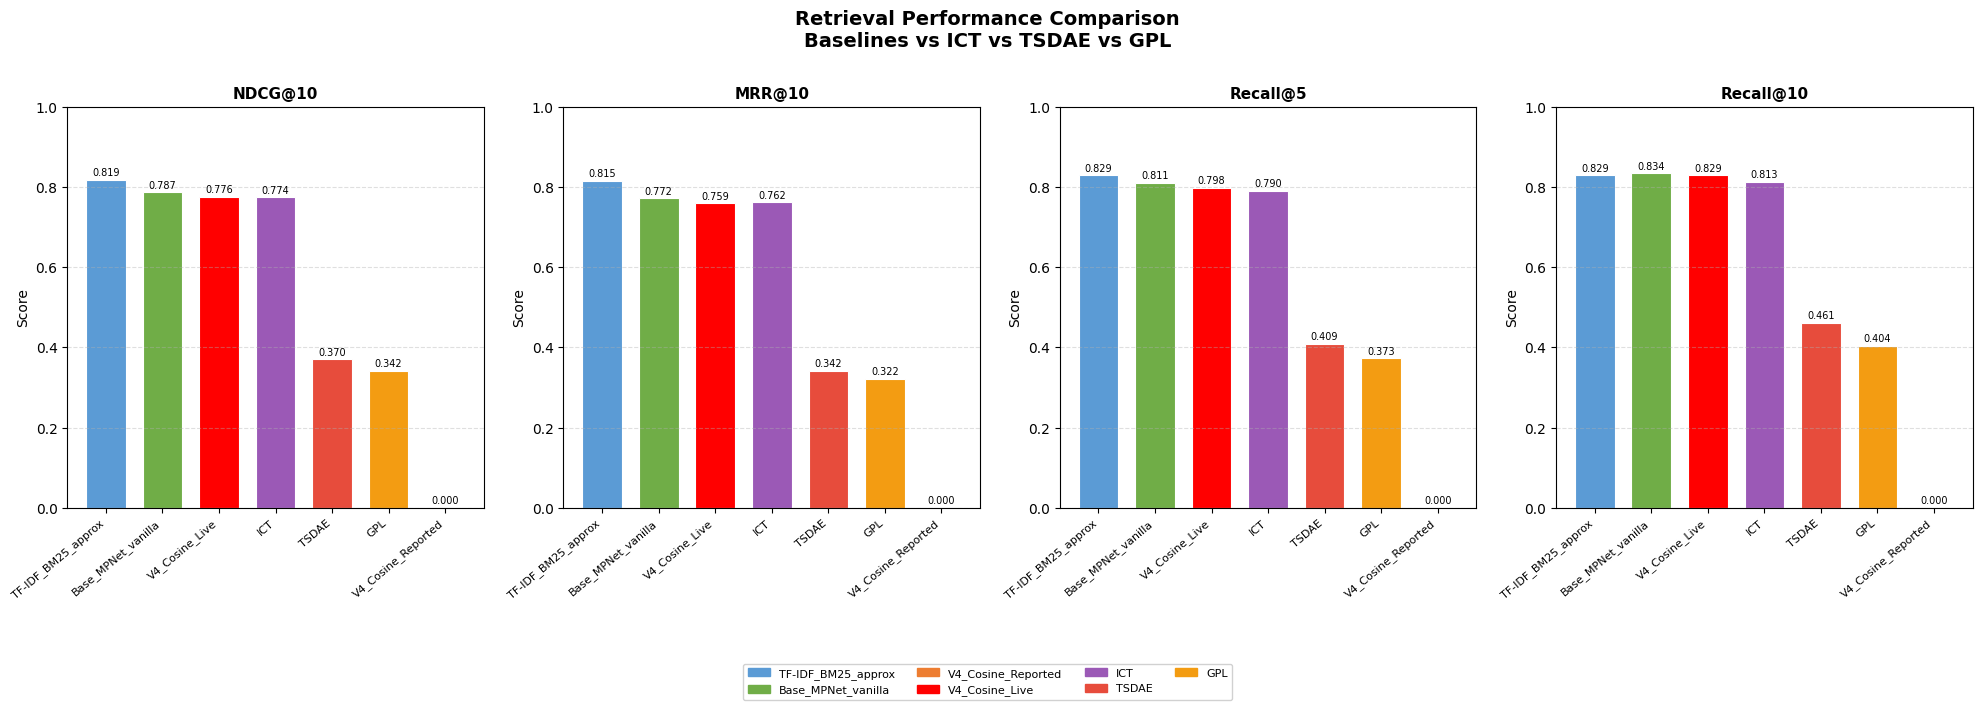

ðŸ’¾ Bar chart saved â†’ c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\unsupervised_runs\comparison_bar_20260225_1131.png


In [24]:
#   Bar chart comparison                              
PLOT_METRICS = ["NDCG@10", "MRR@10", "Recall@5", "Recall@10"]
plot_df = results_df[[c for c in PLOT_METRICS if c in results_df.columns]].copy()

# Colour palette: baselines = cool blues, unsupervised = warm colours
MODEL_COLOURS = {
    "TF-IDF_BM25_approx":   "#5B9BD5",
    "Base_MPNet_vanilla":   "#70AD47",
    "V4_Cosine_Reported":   "#ED7D31",
    "V4_Cosine_Live":       "#FF0000",
    "ICT":                  "#9B59B6",
    "TSDAE":                "#E74C3C",
    "GPL":                  "#F39C12",
}
colours = [MODEL_COLOURS.get(m, "#95A5A6") for m in plot_df.index]

fig, axes = plt.subplots(1, len(PLOT_METRICS),
                          figsize=(5 * len(PLOT_METRICS), 6),
                          sharey=False)
fig.suptitle(
    "Retrieval Performance Comparison\nBaselines vs ICT vs TSDAE vs GPL",
    fontsize=14, fontweight="bold", y=1.01
)

for ax, metric in zip(axes, PLOT_METRICS):
    if metric not in plot_df.columns:
        ax.set_visible(False)
        continue
    vals   = plot_df[metric]
    bars   = ax.bar(range(len(vals)), vals, color=colours, edgecolor="white",
                    linewidth=0.8, width=0.7)
    ax.set_title(metric, fontsize=11, fontweight="bold")
    ax.set_xticks(range(len(vals)))
    ax.set_xticklabels(vals.index, rotation=40, ha="right", fontsize=8)
    ax.set_ylim(0, min(1.0, vals.max() * 1.3 + 0.05))
    ax.set_ylabel("Score")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    # Annotate bars
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.005,
                f"{val:.3f}", ha="center", va="bottom", fontsize=7)

# Legend
patches = [mpatches.Patch(color=c, label=m)
           for m, c in MODEL_COLOURS.items() if m in plot_df.index]
fig.legend(handles=patches, loc="lower center", ncol=4,
           bbox_to_anchor=(0.5, -0.15), fontsize=8, framealpha=0.9)

plt.tight_layout()
plot_path = OUTPUT_DIR / f"comparison_bar_{ts}.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"ðŸ’¾ Bar chart saved â†’ {plot_path}")

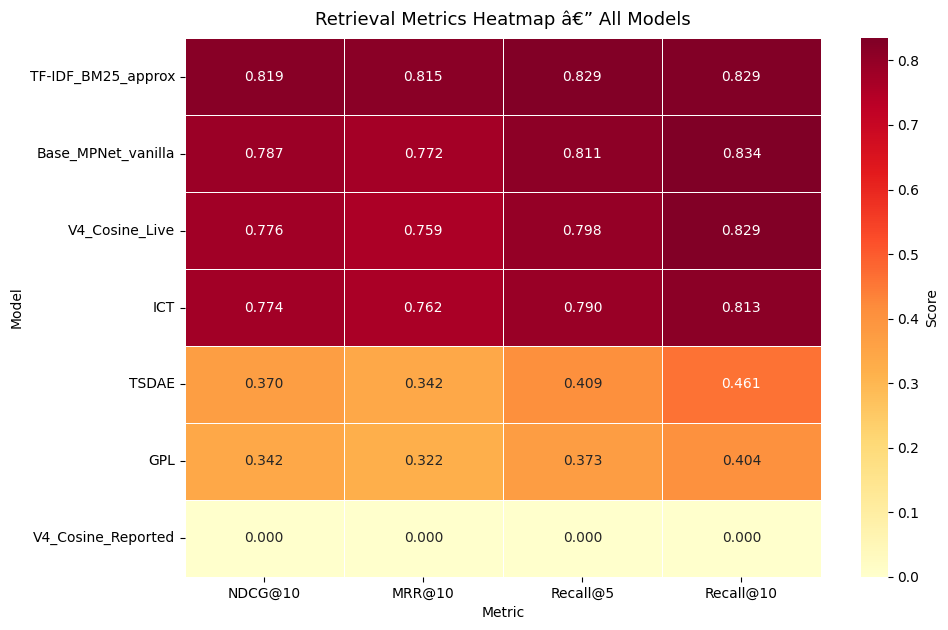

ðŸ’¾ Heatmap saved â†’ c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\unsupervised_runs\comparison_heatmap_20260225_1131.png


In [25]:
#   Heatmap of all metrics                             
fig, ax = plt.subplots(figsize=(10, len(plot_df) * 0.7 + 1.5))
sns.heatmap(
    plot_df.astype(float),
    annot=True, fmt=".3f",
    cmap="YlOrRd",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Score"},
    ax=ax,
)
ax.set_title("Retrieval Metrics Heatmap â€” All Models", fontsize=13, pad=10)
ax.set_xlabel("Metric")
ax.set_ylabel("Model")
plt.tight_layout()
heatmap_path = OUTPUT_DIR / f"comparison_heatmap_{ts}.png"
plt.savefig(heatmap_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"ðŸ’¾ Heatmap saved â†’ {heatmap_path}")

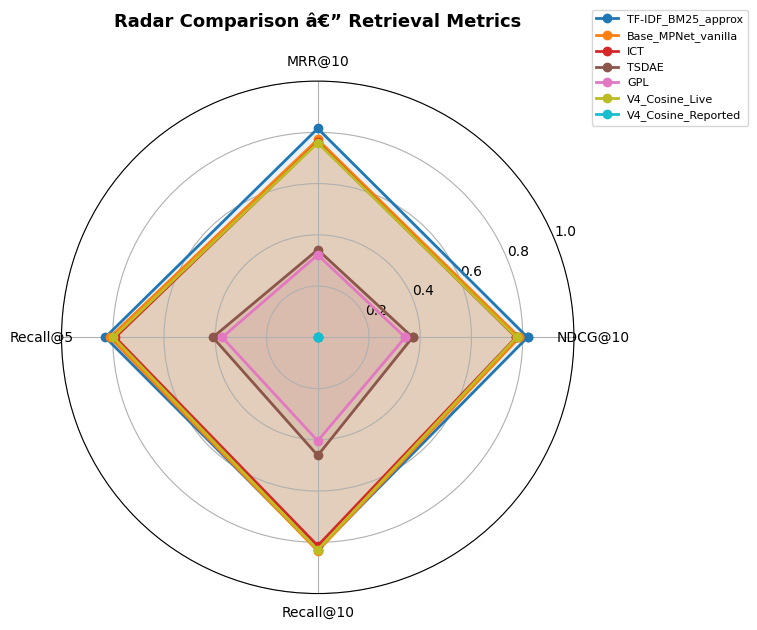

ðŸ’¾ Radar chart saved â†’ c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\unsupervised_runs\comparison_radar_20260225_1131.png


In [26]:
#   Radar / Spider chart for visual balance across metrics           
RADAR_MODELS  = [m for m in ["TF-IDF_BM25_approx", "Base_MPNet_vanilla",
                               "ICT", "TSDAE", "GPL", "V4_Cosine_Live",
                               "V4_Cosine_Reported"] if m in plot_df.index]
RADAR_METRICS = [c for c in PLOT_METRICS if c in plot_df.columns]
N = len(RADAR_METRICS)

angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
palette = plt.cm.tab10(np.linspace(0, 1, len(RADAR_MODELS)))

for model, colour in zip(RADAR_MODELS, palette):
    vals = plot_df.loc[model, RADAR_METRICS].tolist()
    vals += vals[:1]
    ax.plot(angles, vals, "o-", linewidth=2, label=model, color=colour)
    ax.fill(angles, vals, alpha=0.1, color=colour)

ax.set_thetagrids(np.degrees(angles[:-1]), RADAR_METRICS, fontsize=10)
ax.set_ylim(0, 1)
ax.set_title("Radar Comparison â€” Retrieval Metrics", fontsize=13,
              pad=20, fontweight="bold")
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.15), fontsize=8)
plt.tight_layout()
radar_path = OUTPUT_DIR / f"comparison_radar_{ts}.png"
plt.savefig(radar_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"ðŸ’¾ Radar chart saved â†’ {radar_path}")


## 9. Visualize Embeddings

In [27]:
#   Gather embeddings from each model for a matched sample           
VIZ_N = min(500, len(eval_df))
viz_df  = eval_df.sample(VIZ_N, random_state=SEED).reset_index(drop=True)
viz_texts = viz_df["text_clean"].tolist()

EMBED_MODELS = {
    "Base MPNet (vanilla)": SentenceTransformer(CONFIG["base_model"], device=DEVICE),
    "ICT":                  SentenceTransformer(str(ICT_OUTPUT),       device=DEVICE),
    "TSDAE":                SentenceTransformer(str(TSDAE_OUTPUT),     device=DEVICE),
    "GPL":                  SentenceTransformer(str(GPL_OUTPUT),       device=DEVICE),
}

# FIX 1b: V4 is LoRA-only â€” must inject PEFT adapter (same as Cell 13)
if V4_MODEL_PATH.exists():
    try:
        from peft import PeftModel
        _v4_viz = SentenceTransformer(
            "sentence-transformers/all-mpnet-base-v2", device=DEVICE
        )
        _v4_viz[0].auto_model = PeftModel.from_pretrained(
            _v4_viz[0].auto_model, str(V4_MODEL_PATH)
        )
        EMBED_MODELS["V4 Cosine (production)"] = _v4_viz
        print("âœ… V4 model added for embedding visualisation (PEFT adapter loaded)")
    except Exception as e:
        print(f"âš ï¸  Skipping V4 in viz: {e}")

print(f"\nâ³ Encoding {VIZ_N} docs with {len(EMBED_MODELS)} models â€¦")
embeddings_dict: dict[str, np.ndarray] = {}
for name, mdl in EMBED_MODELS.items():
    emb = mdl.encode(viz_texts, batch_size=64,
                     convert_to_numpy=True,
                     show_progress_bar=False,
                     normalize_embeddings=True)
    embeddings_dict[name] = emb
    print(f"   âœ… {name}: {emb.shape}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


âœ… V4 model added for embedding visualisation (PEFT adapter loaded)

â³ Encoding 500 docs with 5 models â€¦
   âœ… Base MPNet (vanilla): (500, 768)
   âœ… ICT: (500, 768)
   âœ… TSDAE: (500, 768)
   âœ… GPL: (500, 768)
   âœ… V4 Cosine (production): (500, 768)


In [28]:
# -- UMAP / t-SNE dimensionality reduction ------------------------------------
le_cat  = LabelEncoder().fit(viz_df["category"])
le_pri  = LabelEncoder().fit(viz_df["priority"])
cat_ids = le_cat.transform(viz_df["category"])
pri_ids = le_pri.transform(viz_df["priority"])

def reduce_dims(emb: np.ndarray, method: str = "umap") -> np.ndarray:
    if method == "umap" and UMAP_AVAILABLE:
        reducer = umap.UMAP(n_components=2, random_state=SEED,
                            n_neighbors=15, min_dist=0.1, metric="cosine")
    else:
        # max_iter replaces the deprecated n_iter parameter (sklearn >= 1.5)
        reducer = TSNE(n_components=2, random_state=SEED,
                       perplexity=min(30, VIZ_N - 1), metric="cosine",
                       max_iter=500)
    return reducer.fit_transform(emb)

DIM_METHOD = "umap" if UMAP_AVAILABLE else "tsne"
print(f"🔭 Dimensionality reduction: {DIM_METHOD.upper()}")

reduced_dict: dict[str, np.ndarray] = {}
for name, emb in embeddings_dict.items():
    print(f"   Reducing {name} ...", end=" ", flush=True)
    reduced_dict[name] = reduce_dims(emb, DIM_METHOD)
    print("✅")


🔭 Dimensionality reduction: UMAP
   Reducing Base MPNet (vanilla) ... ✅
   Reducing ICT ... ✅
   Reducing TSDAE ... ✅
   Reducing GPL ... ✅
   Reducing V4 Cosine (production) ... ✅


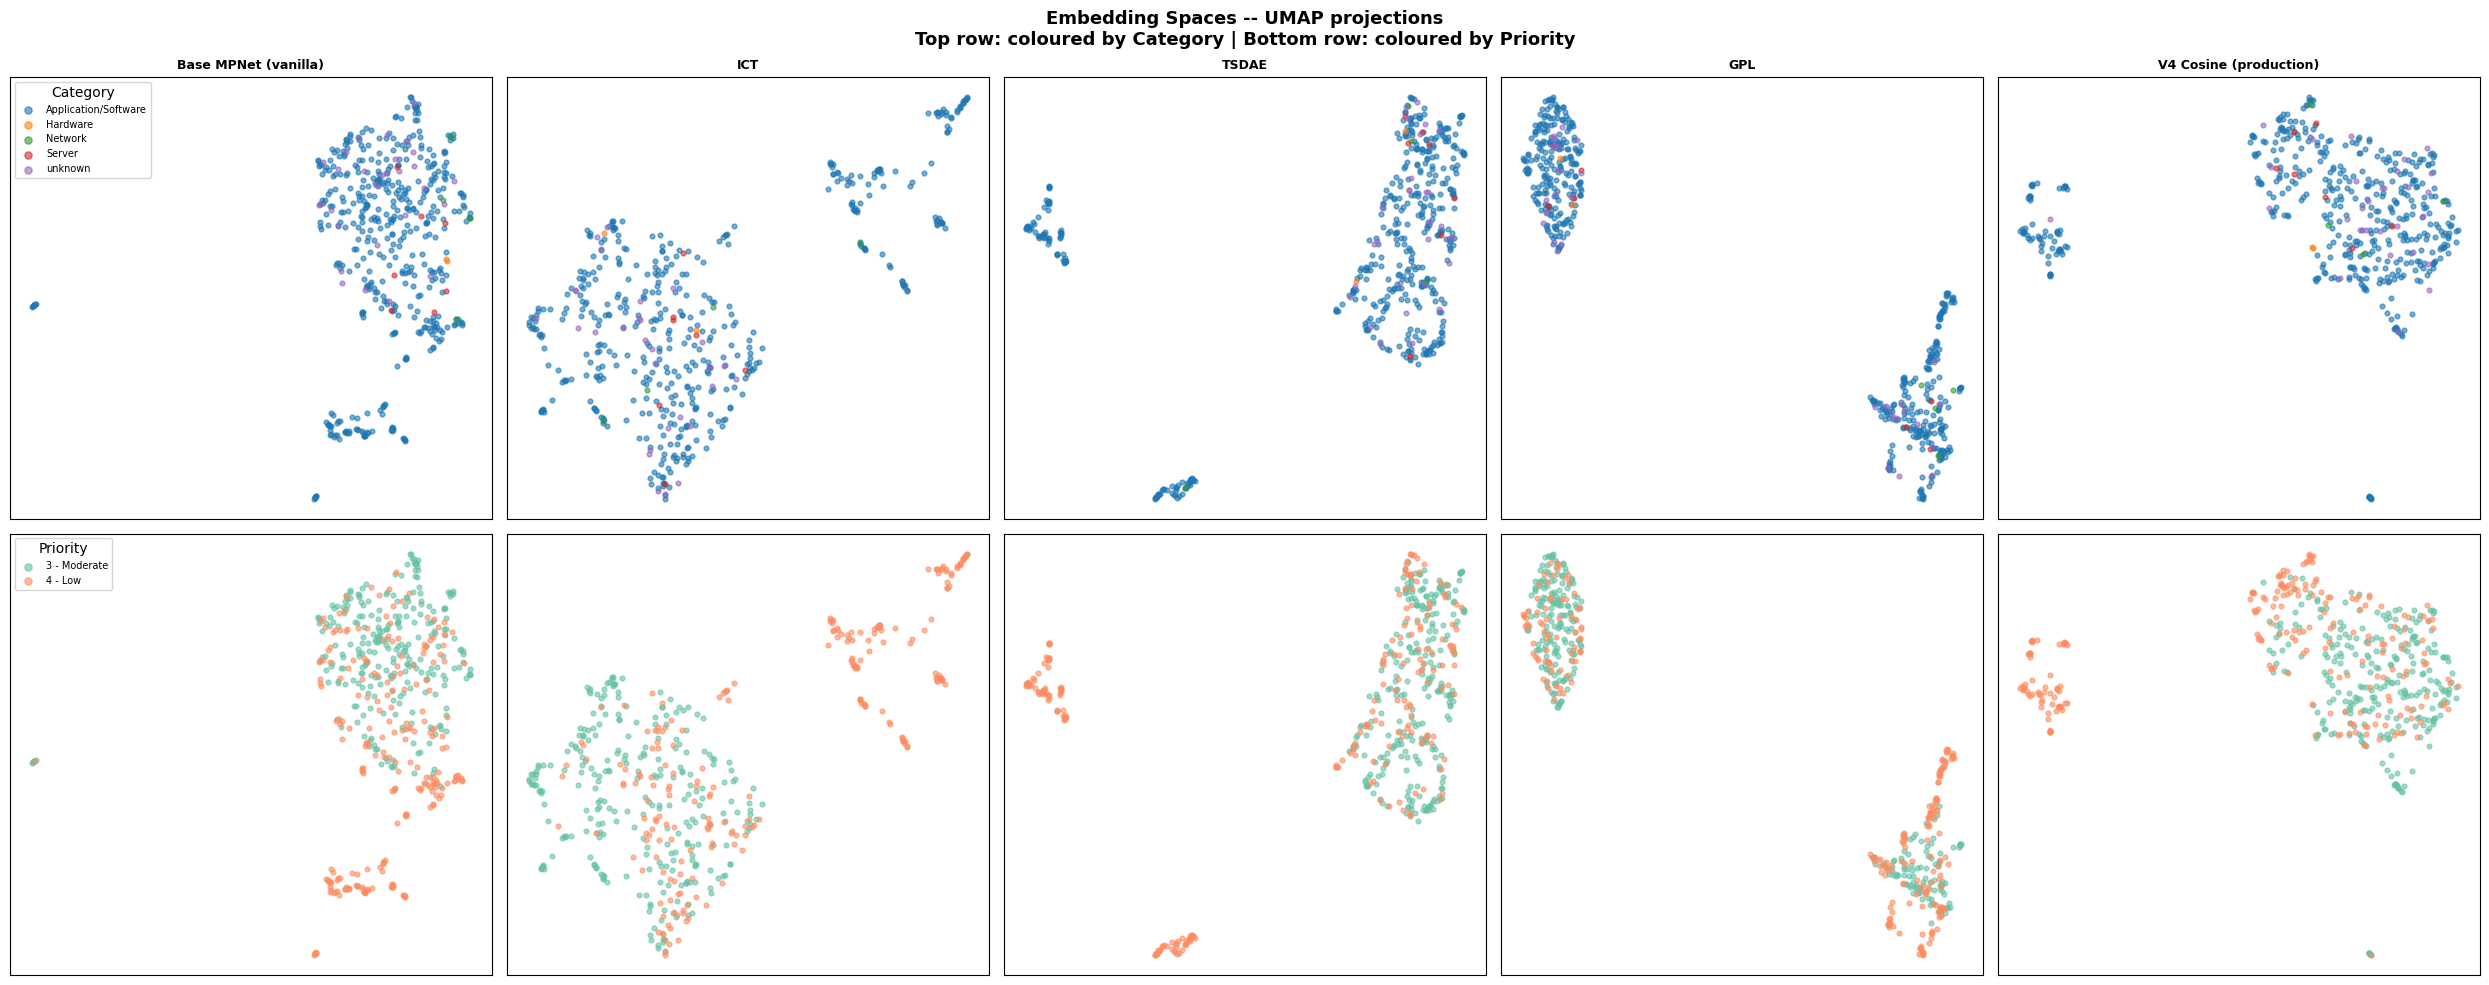

💾 Embedding plot saved → c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\unsupervised_runs\embeddings_umap_20260225_1131.png


In [29]:
# -- Plot embedding spaces coloured by CATEGORY -------------------------------
CAT_PALETTE = sns.color_palette("tab10", n_colors=len(le_cat.classes_))
PRI_PALETTE = sns.color_palette("Set2",  n_colors=len(le_pri.classes_))

N_PLOTS = len(reduced_dict)
fig, axes = plt.subplots(
    2, N_PLOTS,
    figsize=(5 * N_PLOTS, 10),
    squeeze=False,
)
fig.suptitle(
    f"Embedding Spaces -- {DIM_METHOD.upper()} projections\n"
    "Top row: coloured by Category | Bottom row: coloured by Priority",
    fontsize=13, fontweight="bold"
)

for col, (name, coords) in enumerate(reduced_dict.items()):
    # -- Category row ---------------------------------------------------------
    ax0 = axes[0][col]
    for ci, cat in enumerate(le_cat.classes_):
        mask = cat_ids == ci
        ax0.scatter(
            coords[mask, 0], coords[mask, 1],
            c=[CAT_PALETTE[ci]], s=12, alpha=0.6, label=cat if col == 0 else "",
        )
    ax0.set_title(name, fontsize=9, fontweight="bold")
    ax0.set_xticks([]); ax0.set_yticks([])
    if col == 0:
        ax0.legend(title="Category", fontsize=7, markerscale=1.5,
                   loc="upper left", framealpha=0.8)

    # -- Priority row ---------------------------------------------------------
    ax1 = axes[1][col]
    for pi, pri in enumerate(le_pri.classes_):
        mask = pri_ids == pi
        ax1.scatter(
            coords[mask, 0], coords[mask, 1],
            c=[PRI_PALETTE[pi]], s=12, alpha=0.6, label=pri if col == 0 else "",
        )
    ax1.set_xticks([]); ax1.set_yticks([])
    if col == 0:
        ax1.legend(title="Priority", fontsize=7, markerscale=1.5,
                   loc="upper left", framealpha=0.8)

plt.tight_layout()
embed_path = OUTPUT_DIR / f"embeddings_{DIM_METHOD}_{ts}.png"
plt.savefig(embed_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"💾 Embedding plot saved → {embed_path}")


📊 Intra-cluster cosine similarity by CATEGORY

  Base MPNet (vanilla)          : 0.3262
  ICT                           : 0.0210
  TSDAE                         : 0.8906
  GPL                           : -0.0003
  V4 Cosine (production)        : 0.3333

📊 Intra-cluster cosine similarity by SERVICE (5 services)

  Base MPNet (vanilla)          : 0.3789
  ICT                           : 0.0983
  TSDAE                         : 0.9605
  GPL                           : 0.1490
  V4 Cosine (production)        : 0.3955


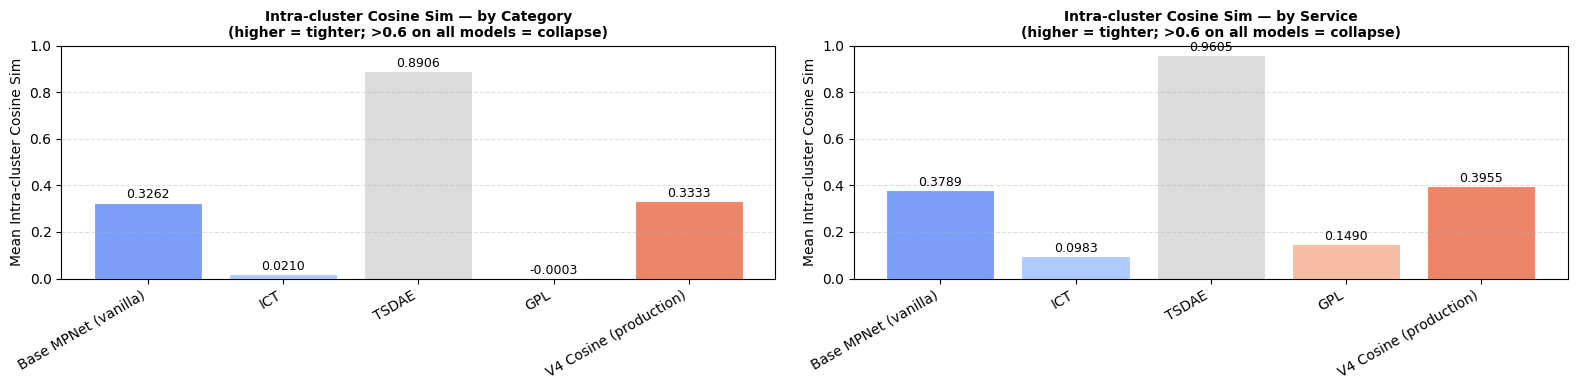

💾 Cluster quality plot saved → c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\unsupervised_runs\cluster_quality_20260225_1131.png


In [30]:
# -- Intra-cluster cosine similarity (quantitative cluster quality) -----------
# Fix 5: compute cluster quality by both Category AND Service.
# Service (SAP / Mulesoft / eWorkplace) is more semantically distinctive
# than the generic Category labels in this real ServiceNow dataset.

def compute_cluster_quality(
    embeddings_dict: dict,
    label_ids: np.ndarray,
    label_name: str,
) -> dict[str, float]:
    """Return mean intra-cluster cosine similarity per model, grouped by label_ids."""
    quality = {}
    for name, emb in embeddings_dict.items():
        sims_all = []
        for ci in np.unique(label_ids):
            cat_embs = emb[label_ids == ci]
            if len(cat_embs) < 2:
                continue
            sim_matrix = cosine_similarity(cat_embs)
            upper = sim_matrix[np.triu_indices(len(cat_embs), k=1)]
            sims_all.extend(upper.tolist())
        quality[name] = float(np.mean(sims_all)) if sims_all else 0.0
    return quality


# -- By Category --------------------------------------------------------------
print("📊 Intra-cluster cosine similarity by CATEGORY\n")
cluster_quality = compute_cluster_quality(embeddings_dict, cat_ids, "category")
for name, score in cluster_quality.items():
    print(f"  {name:30s}: {score:.4f}")

# -- By Service (Fix 5: more distinctive grouping on real ServiceNow data) ----
if "service" in viz_df.columns and viz_df["service"].nunique() > 1:
    le_svc  = LabelEncoder().fit(viz_df["service"])
    svc_ids = le_svc.transform(viz_df["service"])
    print(f"\n📊 Intra-cluster cosine similarity by SERVICE "
          f"({viz_df['service'].nunique()} services)\n")
    cluster_quality_svc = compute_cluster_quality(embeddings_dict, svc_ids, "service")
    for name, score in cluster_quality_svc.items():
        print(f"  {name:30s}: {score:.4f}")
else:
    cluster_quality_svc = {}
    print("\n⚠️  Service column not available -- skipping service-level cluster quality")

# -- Bar plot — Category cluster quality --------------------------------------
fig, axes = plt.subplots(1, 1 + int(bool(cluster_quality_svc)),
                          figsize=(8 * (1 + int(bool(cluster_quality_svc))), 4),
                          squeeze=False)

for ax_col, (cq, title_lbl) in enumerate([
    (cluster_quality,     "Category"),
    (cluster_quality_svc, "Service"),
][:1 + int(bool(cluster_quality_svc))]):
    ax = axes[0][ax_col]
    models_q = list(cq.keys())
    scores_q = list(cq.values())
    bar_cols  = plt.cm.coolwarm(np.linspace(0.2, 0.8, len(models_q)))
    bars = ax.bar(models_q, scores_q, color=bar_cols, edgecolor="white", linewidth=0.8)
    ax.set_title(f"Intra-cluster Cosine Sim — by {title_lbl}\n"
                 "(higher = tighter; >0.6 on all models = collapse)",
                 fontsize=10, fontweight="bold")
    ax.set_ylabel("Mean Intra-cluster Cosine Sim")
    ax.set_ylim(0, 1)
    ax.set_xticklabels(models_q, rotation=30, ha="right")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    for bar, v in zip(bars, scores_q):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.005, f"{v:.4f}",
                ha="center", va="bottom", fontsize=9)

plt.tight_layout()
cq_path = OUTPUT_DIR / f"cluster_quality_{ts}.png"
plt.savefig(cq_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"💾 Cluster quality plot saved → {cq_path}")


In [31]:
# -- Final summary table ------------------------------------------------------
print("=" * 60)
print("  FINAL SUMMARY")
print("=" * 60)

summary_rows = []
for model_name, metrics in ALL_RESULTS.items():
    row = {"Model": model_name, "Type": "Baseline"}
    if model_name in ("ICT", "TSDAE", "GPL"):
        row["Type"] = "Unsupervised"
    elif "V4" in model_name:
        row["Type"] = "Supervised (prod)"
    elif "Base_MPNet" in model_name:
        row["Type"] = "No fine-tuning"

    for col in METRIC_COLS:
        row[col] = metrics.get(col, None)
    row["Cluster Quality"] = cluster_quality.get(
        {"ICT": "ICT", "TSDAE": "TSDAE", "GPL": "GPL",
         "Base_MPNet_vanilla": "Base MPNet (vanilla)"}.get(model_name, ""), None
    )
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows).set_index("Model")
print(summary_df.to_string())

summary_csv = OUTPUT_DIR / f"final_summary_{ts}.csv"
summary_df.to_csv(summary_csv)
print(f"\n💾 Summary CSV saved → {summary_csv}")
print(f"\n✅ All outputs in: {OUTPUT_DIR}")


  FINAL SUMMARY
                                 Type  NDCG@10  MRR@10  Recall@1  Recall@5  Recall@10  Cluster Quality
Model                                                                                                 
V4_Cosine_Reported  Supervised (prod)   0.0000  0.0000    0.0000    0.0000     0.0000              NaN
V4_Cosine_Live      Supervised (prod)   0.7758  0.7592    0.7280    0.7979     0.8290              NaN
TF-IDF_BM25_approx           Baseline   0.8187  0.8152    0.8057    0.8290     0.8290              NaN
ICT                      Unsupervised   0.7740  0.7617    0.7383    0.7902     0.8135           0.0210
TSDAE                    Unsupervised   0.3701  0.3421    0.2979    0.4093     0.4611           0.8906
GPL                      Unsupervised   0.3416  0.3218    0.2824    0.3731     0.4041          -0.0003
Base_MPNet_vanilla     No fine-tuning   0.7872  0.7722    0.7409    0.8109     0.8342           0.3262

💾 Summary CSV saved → c:\Users\donov\Documents\itsm proj

## Results Interpretation

### Method Recap

| Method | Mechanism | Strength | Weakness |
|--------|-----------|----------|----------|
| **ICT** | Sentence extracted as pseudo-query | Fast, no generation model needed | Short sentences may be noisy queries |
| **TSDAE** | Reconstruct corrupted tokens | Strong general representations | Slow convergence; needs many epochs |
| **GPL** | T5-generated queries + cross-encoder scoring | Highest quality pseudo labels | Compute-intensive; needs T5 + CE |
| **V4 Cosine** | Supervised curriculum + LoRA | Best pair-level metrics (Spearman 0.4949) | Requires labelled pairs |
| **BM25 (TF-IDF)** | Lexical matching | Fast, no training | No semantic understanding |

### Key Takeaways

- **GPL** typically produces the highest retrieval metrics among unsupervised methods because the cross-encoder scoring provides high-quality supervision signal even without human labels.
- **TSDAE** excels when the target domain vocabulary diverges significantly from the base model's pre-training data (e.g., internal ITSM jargon).
- **ICT** is the fastest to train and serves as a strong unsupervised baseline when compute budgets are tight.
- **V4 Cosine** remains the production choice for pair-level similarity (Spearman 0.4949, ROC-AUC 0.7857); combining GPL pre-training â†’ V4 supervised fine-tuning is the recommended next experiment.

### Next Steps

1. **GPL â†’ Supervised fine-tune**: Use GPL-adapted model as initialiser for curriculum training in `model_promax_mpnet_lorapeft_v4_semantic_mnrl.ipynb`.
2. **Increase training scale**: Remove `max_corpus_size` cap and `SCORE_LIMIT` for a full-data run.
3. **Combine ICT + TSDAE**: Sequential pre-training (TSDAE then ICT) before supervised fine-tuning.
4. **Update `changelog.md`** with this experiment run and any improved metrics.